In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv('/run/media/ezreals_/EXTERNAL/Code/NoteBook/MachineLearning/Week9/Dataset/CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [2]:
# Sl_No dan Customer Key hanya ID, tidak dipakai
features = ['Avg_Credit_Limit','Total_Credit_Cards','Total_visits_bank','Total_visits_online','Total_calls_made']
X = StandardScaler().fit_transform(df[features])

model = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['Cluster'] = model.fit_predict(X)
df['Cluster'].value_counts()

Cluster
0    385
1    225
2     50
Name: count, dtype: int64

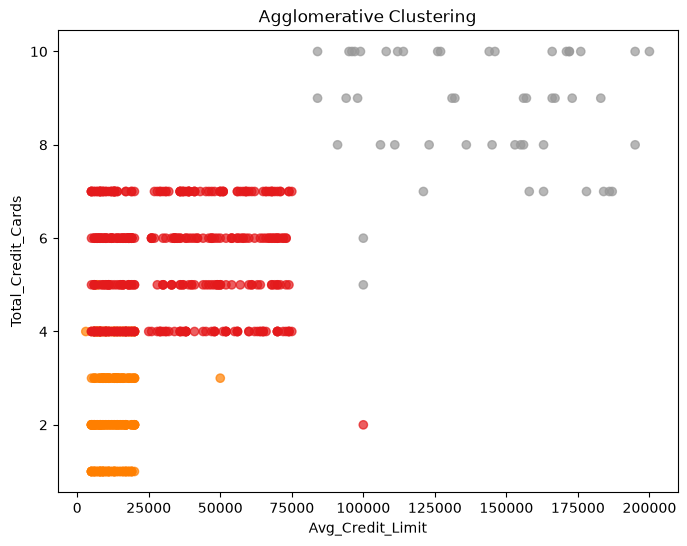

In [3]:
plt.figure(figsize=(8,6))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], c=df['Cluster'], cmap='Set1', alpha=0.7)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Agglomerative Clustering')
plt.show()

In [4]:
print('Silhouette Score :', silhouette_score(X, df['Cluster']))
print('Davies-Bouldin   :', davies_bouldin_score(X, df['Cluster']))

Silhouette Score : 0.5147639589977819
Davies-Bouldin   : 0.680959518994733
